<a href="https://colab.research.google.com/github/Syed-san/SciReason-AI/blob/main/MAAI902_SciReasonAI_Complete_Run_and_Submit_FP16_Fix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scientific Reasoning and Explanation with Qwen2.5-0.5B
**Individual practical task — MAAI 902: Natural Language Processing & LLMs**

## Research question
How do fine-tuning hyperparameters affect the learning behaviour and generated science explanations of a pretrained causal language model?

## 1. Setup and reproducibility
 The model is `Qwen/Qwen2.5-0.5B`, a compact pretrained causal language model. The experiment uses full fine-tuning to keep the pipeline aligned with the assignment's language-modelling objective.

The dataset loader below checks the available columns and formats records defensively. If the dataset repository or its schema changes, inspect the printed columns and update the field mapping rather than silently substituting unrelated data.

**Mixed precision note:** On CUDA, this notebook loads the model in FP16 and enables FP16 training while explicitly disabling BF16. On CPU, it uses FP32. If your runtime still reports a precision/scaler error, switch to FP32 by setting `fp16=False` in Cell 11 and loading the model with `torch.float32`.


In [1]:

import torch
import transformers
import datasets
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
Transformers: 5.21.0
Datasets: 4.8.5
GPU available: True


In [2]:
import os, re, gc, json, math, random, inspect, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments,
    TrainerCallback, DataCollatorForLanguageModeling, set_seed
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_NAME = "Qwen/Qwen2.5-0.5B"
DATASET_NAME = "derek-thomas/ScienceQA"
BLOCK_SIZE = 128

# Compute-friendly starting limits. Increase after the first successful run if time allows.
MAX_TRAIN_ROWS = 400
MAX_VALIDATION_ROWS = 80
OUTPUT_DIR = Path("/content/scientific_reasoning_project")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Choose a GPU runtime in Colab for practical training time.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Load and inspect the science dataset
We use ScienceQA as the domain source because its records include science questions and, depending on the record/schema, answer choices, hints, lectures, or solutions. The code will print the actual schema so the data handling can be verified. Only public dataset content should be used; do not add private or personally identifiable data.

In [3]:
dataset = load_dataset(DATASET_NAME)
print(dataset)
print("Available splits:", list(dataset.keys()))
first_split = dataset["train"] if "train" in dataset else dataset[list(dataset.keys())[0]]
print("Columns:", first_split.column_names)
print("Example record:")
print(first_split[0])

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

data/train-00000-of-00001-1028f23e353fbe(…): reconstructing file:   0%|          |  0.00B /  377MB            

data/train-00000-of-00001-1028f23e353fbe(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-6c7328ff6(…): reconstructing file:   0%|          |  0.00B /  126MB            

data/validation-00000-of-00001-6c7328ff6(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-f0e719df791966f(…): reconstructing file:   0%|          |  0.00B /  122MB            

data/test-00000-of-00001-f0e719df791966f(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12726 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4241 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4241 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 12726
    })
    validation: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 4241
    })
    test: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 4241
    })
})
Available splits: ['train', 'validation', 'test']
Columns: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution']
Example record:
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=750x429 at 0x782DD02530E0>, 'question': 'Which of these states is farthest north?', 'choices': ['West 

In [4]:
def as_text(value):
    if value is None:
        return ""
    if isinstance(value, dict):
        if "text" in value:
            return str(value["text"])
        return " ".join(f"{k}: {v}" for k, v in value.items())
    if isinstance(value, (list, tuple)):
        return " ".join(as_text(v) for v in value)
    return str(value)

def pick(record, names):
    for name in names:
        if name in record and record[name] is not None:
            val = as_text(record[name]).strip()
            if val and val.lower() not in {"none", "nan"}:
                return val
    return ""

def format_science_record(record):
    question = pick(record, ["question", "Question", "query", "problem", "instruction"])
    raw_choices = record.get("choices", record.get("options", record.get("answer_choices", [])))
    if isinstance(raw_choices, dict) and "text" in raw_choices:
        raw_choices = raw_choices["text"]
    if not isinstance(raw_choices, (list, tuple)):
        raw_choices = [raw_choices] if raw_choices else []
    choice_labels = [f"{chr(65+i)}. {as_text(choice).strip()}" for i, choice in enumerate(raw_choices)]
    choices = " ".join(choice_labels)

    raw_answer = record.get("answer", record.get("answerKey", record.get("correct_answer", record.get("label", ""))))
    answer = ""
    if isinstance(raw_answer, (int, np.integer)) and raw_choices and 0 <= int(raw_answer) < len(raw_choices):
        answer = f"{chr(65+int(raw_answer))}. {as_text(raw_choices[int(raw_answer)]).strip()}"
    elif isinstance(raw_answer, str) and raw_answer.strip().isdigit() and raw_choices:
        answer_idx = int(raw_answer.strip())
        if 0 <= answer_idx < len(raw_choices):
            answer = f"{chr(65+answer_idx)}. {as_text(raw_choices[answer_idx]).strip()}"
        else:
            answer = raw_answer.strip()
    else:
        answer = as_text(raw_answer).strip()

    explanation = pick(record, ["solution", "explanation", "rationale", "lecture", "hint", "answer_explanation"])
    subject = pick(record, ["subject", "topic", "category"])
    pieces = []
    if subject:
        pieces.append(f"Subject: {subject}")
    if question:
        pieces.append(f"Question: {question}")
    if choices:
        pieces.append(f"Choices: {choices}")
    if answer:
        pieces.append(f"Answer: {answer}")
    if explanation:
        pieces.append(f"Explanation: {explanation}")
    return "\n".join(pieces).strip()

train_split = dataset["train"] if "train" in dataset else dataset[list(dataset.keys())[0]]
val_key = next((k for k in ["validation", "dev", "test"] if k in dataset), None)
val_split = dataset[val_key] if val_key else None

all_train_records = [format_science_record(r) for r in train_split]
all_train_records = [t for t in all_train_records if len(t.split()) >= 12]
all_val_records = [format_science_record(r) for r in val_split] if val_split is not None else []
all_val_records = [t for t in all_val_records if len(t.split()) >= 12]

if len(all_train_records) < 100:
    raise ValueError("Fewer than 100 usable training records were found. Inspect the dataset schema and update format_science_record().")

def sentence_count(text):
    return len([s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if len(s.split()) >= 3])

# Start with a compute-friendly subset, then expand until the assignment's
# minimum of 500 sentence-like units is reached.
train_records = all_train_records[:MAX_TRAIN_ROWS]
sentence_total = sum(sentence_count(t) for t in train_records)
while sentence_total < 500 and len(train_records) < len(all_train_records):
    next_size = min(len(all_train_records), max(len(train_records) + 100, len(train_records) * 2))
    train_records = all_train_records[:next_size]
    sentence_total = sum(sentence_count(t) for t in train_records)

if sentence_total < 500:
    raise ValueError(f"Corpus has only {sentence_total} sentence-like units. The assignment requires at least 500; inspect the formatter or use more source records.")

if all_val_records:
    val_records = all_val_records[:MAX_VALIDATION_ROWS]
else:
    cut = max(1, int(len(train_records) * 0.15))
    val_records = train_records[-cut:]
    train_records = train_records[:-cut]

corpus_text = "\n\n".join(train_records)
print(f"Training documents: {len(train_records)}")
print(f"Validation documents: {len(val_records)}")
print(f"Approximate domain-specific sentences in training corpus: {sentence_total}")
print("Example formatted record:\n", train_records[0][:1200])
print("\nCorpus sentence requirement met for this prepared subset.")

Training documents: 400
Validation documents: 80
Approximate domain-specific sentences in training corpus: 3748
Example formatted record:
 Subject: social science
Question: Which of these states is farthest north?
Choices: A. West Virginia B. Louisiana C. Arizona D. Oklahoma
Answer: A. West Virginia
Explanation: To find the answer, look at the compass rose. Look at which way the north arrow is pointing. West Virginia is farthest north.

Corpus sentence requirement met for this prepared subset.


## 3. Tokenization and fixed-length PyTorch Dataset
The task specifies `block_size=128`. We tokenize the training and validation text separately and split each token stream into fixed-length blocks. This is causal language modelling: the model learns to predict the next token from previous tokens. A block may contain the end of one formatted record and the beginning of another; record separators reduce ambiguity.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def make_token_blocks(texts, tokenizer, block_size=BLOCK_SIZE):
    joined = ("\n" + tokenizer.eos_token + "\n").join(texts)
    token_ids = tokenizer(joined, add_special_tokens=False, truncation=False)["input_ids"]
    # Keep only complete fixed-size blocks.
    usable = (len(token_ids) // block_size) * block_size
    token_ids = token_ids[:usable]
    return [token_ids[i:i+block_size] for i in range(0, usable, block_size)]

class FixedBlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        ids = torch.tensor(self.blocks[idx], dtype=torch.long)
        return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}

train_blocks = make_token_blocks(train_records, tokenizer)
val_blocks = make_token_blocks(val_records, tokenizer)
train_ds = FixedBlockDataset(train_blocks)
eval_ds = FixedBlockDataset(val_blocks)

print("Train token blocks:", len(train_ds))
print("Validation token blocks:", len(eval_ds))
print("Block size:", BLOCK_SIZE)
if len(train_ds) < 10 or len(eval_ds) < 2:
    raise ValueError("Too few token blocks. Increase the number of source records or inspect preprocessing.")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Train token blocks: 433
Validation token blocks: 85
Block size: 128


## 4. Training callback and experiment configuration
The reference run uses the exact assignment defaults: learning rate `5e-4`, 5 epochs, and batch size 4. The callback stores training loss every 5 steps. Experiments below vary one hyperparameter at a time; all other settings stay at the reference values. A very small learning rate is included as a candidate underfitting run, but underfitting must be confirmed from the actual results.

In [6]:
class LossHistoryCallback(TrainerCallback):
    def __init__(self):
        self.steps = []
        self.losses = []
        self.eval_steps = []
        self.eval_losses = []
    def on_log(self, args, state, control, logs=None, **kwargs):
        logs = logs or {}
        step = int(state.global_step)
        if "loss" in logs:
            self.steps.append(step)
            self.losses.append(float(logs["loss"]))
        if "eval_loss" in logs:
            self.eval_steps.append(step)
            self.eval_losses.append(float(logs["eval_loss"]))

REFERENCE = {
    "learning_rate": 5e-4,
    "num_train_epochs": 5,
    "per_device_train_batch_size": 4,
}
EXPERIMENTS = [
    {"name": "Reference", "learning_rate": 5e-4, "num_train_epochs": 5, "per_device_train_batch_size": 4},
    {"name": "Very low LR (1e-6)", "learning_rate": 1e-6, "num_train_epochs": 5, "per_device_train_batch_size": 4},
    {"name": "High LR (1e-3)", "learning_rate": 1e-3, "num_train_epochs": 5, "per_device_train_batch_size": 4},
    {"name": "One epoch", "learning_rate": 5e-4, "num_train_epochs": 1, "per_device_train_batch_size": 4},
    {"name": "Batch size 2", "learning_rate": 5e-4, "num_train_epochs": 5, "per_device_train_batch_size": 2},
]
pd.DataFrame(EXPERIMENTS)

,name,learning_rate,num_train_epochs,per_device_train_batch_size
0,Reference,0.000500,5,4
1,Very low LR (1e-6),0.000001,5,4
2,High LR (1e-3),0.001000,5,4
3,One epoch,0.000500,1,4
4,Batch size 2,0.000500,5,2


In [9]:
def build_training_args(run_dir, exp):
    """Build Trainer arguments with explicit FP16/FP32 selection."""
    params = inspect.signature(TrainingArguments.__init__).parameters

    use_fp16 = bool(torch.cuda.is_available())
    kwargs = dict(
        output_dir=str(run_dir),
        learning_rate=exp["learning_rate"],
        num_train_epochs=exp["num_train_epochs"],
        per_device_train_batch_size=exp["per_device_train_batch_size"],
        per_device_eval_batch_size=4,
        logging_steps=5,
        logging_strategy="steps",
        save_strategy="no",
        report_to="none",
        seed=SEED,
        data_seed=SEED,
        fp16=use_fp16,
        gradient_checkpointing=False,
        dataloader_num_workers=0,
        remove_unused_columns=False,
    )

    # Explicitly disable BF16; FP16 is used on CUDA, FP32 on CPU.
    if "bf16" in params:
        kwargs["bf16"] = False

    if "eval_strategy" in params:
        kwargs["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in params:
        kwargs["evaluation_strategy"] = "epoch"

    return TrainingArguments(**kwargs)


collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)


def run_experiment(exp):
    run_name = exp["name"]
    safe_name = re.sub(r"[^a-zA-Z0-9_-]+", "_", run_name)
    run_dir = OUTPUT_DIR / safe_name
    run_dir.mkdir(parents=True, exist_ok=True)
    history = LossHistoryCallback()

    # Load weights explicitly as FP16 on CUDA to avoid accidental BF16 weights.
    model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
)
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.use_cache = False

    args = build_training_args(run_dir, exp)
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=collator,
        callbacks=[history],
    )

    train_result = trainer.train()
    eval_result = trainer.evaluate()

    final_model_dir = run_dir / "final_model"
    trainer.save_model(str(final_model_dir))
    tokenizer.save_pretrained(str(final_model_dir))

    result = {
        "name": run_name,
        "config": exp,
        "train_loss_final": float(train_result.training_loss),
        "eval_loss": float(eval_result.get("eval_loss", float("nan"))),
        "steps": history.steps,
        "losses": history.losses,
        "eval_steps": history.eval_steps,
        "eval_losses": history.eval_losses,
        "model_dir": str(final_model_dir),
    }

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result


## 5. Run the reference model and hyperparameter experiments
This section performs five runs: one reference and four controlled experiments. Each run starts from the same pretrained checkpoint so the comparison isolates the changed configuration as much as possible. Full fine-tuning can take time; keep Colab connected and use a GPU. If you are short on time, first test the notebook with only the reference run by temporarily setting `EXPERIMENTS = EXPERIMENTS[:1]`, then restore all experiments for the final evidence.

In [10]:
results = []
for i, exp in enumerate(EXPERIMENTS, start=1):
    print(f"\n{'='*80}\nRun {i}/{len(EXPERIMENTS)}: {exp['name']}\n{'='*80}")
    result = run_experiment(exp)
    results.append(result)
    print(pd.DataFrame([{
        "run": result["name"],
        "training_loss": result["train_loss_final"],
        "validation_loss": result["eval_loss"],
        "steps_logged": len(result["steps"])
    }]).to_string(index=False))


Run 1/5: Reference


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.448899,3.434207
2,1.603526,2.948581
3,0.748867,2.941492
4,0.296262,3.002418
5,0.180888,2.999478


Training Loss,Validation Loss,Epoch
0.180888,2.999478,5


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

      run  training_loss  validation_loss  steps_logged
Reference       1.506112         2.999478           109

Run 2/5: Very low LR (1e-6)


... (16 outputs left out)

Epoch,Training Loss,Validation Loss
1,4.105306,3.955888
2,1.947897,3.374858
3,1.061470,3.287297
4,0.391765,3.373451
5,0.232583,3.512133


Training Loss,Validation Loss,Epoch
0.232583,3.512133,5


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

         run  training_loss  validation_loss  steps_logged
Batch size 2       1.774331         3.512133           217


## 6. Visualise and compare the loss curves
All logged training losses are plotted on one axis with a legend, including the reference run. The chart is generated from the actual callback logs. A high learning rate or a short training run may not fail visibly; discuss only patterns supported by your curves.

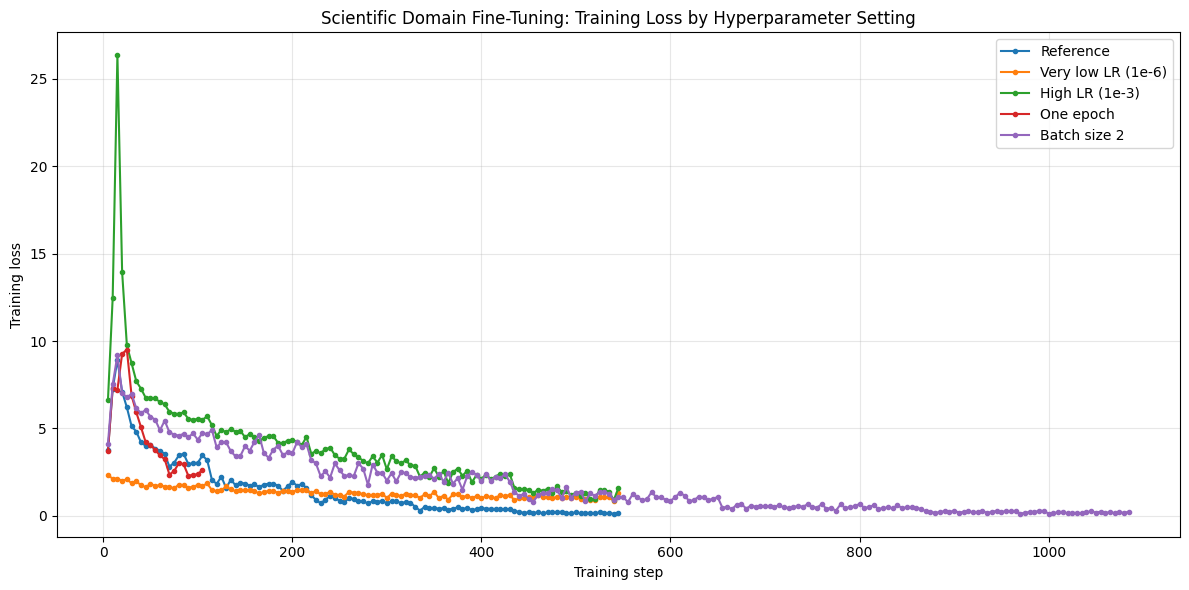

Saved: /content/scientific_reasoning_project/all_training_loss_curves.png


,Run,Learning rate,Epochs,Batch size,Final training loss,Validation loss
1,Very low LR (1e-6),0.000001,5,4,1.325592,1.463302
3,One epoch,0.000500,1,4,4.419661,2.512753
0,Reference,0.000500,5,4,1.506112,2.999478
4,Batch size 2,0.000500,5,2,1.774331,3.512133
2,High LR (1e-3),0.001000,5,4,3.913638,4.270192


In [11]:
plt.figure(figsize=(12, 6))
for r in results:
    if r["steps"] and r["losses"]:
        plt.plot(r["steps"], r["losses"], marker=".", linewidth=1.5, label=r["name"])
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.title("Scientific Domain Fine-Tuning: Training Loss by Hyperparameter Setting")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
loss_plot_path = OUTPUT_DIR / "all_training_loss_curves.png"
plt.savefig(loss_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", loss_plot_path)

summary = pd.DataFrame([{
    "Run": r["name"],
    "Learning rate": r["config"]["learning_rate"],
    "Epochs": r["config"]["num_train_epochs"],
    "Batch size": r["config"]["per_device_train_batch_size"],
    "Final training loss": r["train_loss_final"],
    "Validation loss": r["eval_loss"],
} for r in results])
display(summary.sort_values("Validation loss"))

## 7. Generate side-by-side outputs from the base and fine-tuned models
Use the same prompt for the base model and each fine-tuned variant. The generated answers are qualitative evidence, not a substitute for a benchmark. Look for scientific relevance, coherence, whether the model explains its answer, and whether it invents unsupported claims.

In [12]:
def generate_text(model, prompt, max_new_tokens=100):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.7,
            top_p=0.9,
            repetition_penalty=1.1,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    return tokenizer.decode(output[0], skip_special_tokens=True)

PROMPT = (
    "Question: Why does the Moon appear to change shape during the month?\n"
    "Answer with the correct scientific explanation and a short step-by-step rationale.\n"
    "Explanation:"
)

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
base_model.config.pad_token_id = tokenizer.pad_token_id
if torch.cuda.is_available():
    base_model = base_model.to("cuda")
base_output = generate_text(base_model, PROMPT)
del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

generation_rows = [{"Model": "Base model", "Output": base_output}]
for r in results:
    tuned = AutoModelForCausalLM.from_pretrained(r["model_dir"])
    tuned.config.pad_token_id = tokenizer.pad_token_id
    if torch.cuda.is_available():
        tuned = tuned.to("cuda")
    generated = generate_text(tuned, PROMPT)
    generation_rows.append({"Model": r["name"], "Output": generated})
    del tuned
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

for row in generation_rows:
    print("\n" + "="*90)
    print(row["Model"])
    print("-"*90)
    print(row["Output"])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Base model
------------------------------------------------------------------------------------------
Question: Why does the Moon appear to change shape during the month?
Answer with the correct scientific explanation and a short step-by-step rationale.
Explanation: The Moon appears to be changing its shape because it is moving around Earth, which means that the Sun and Earth are also moving around each other. When the Moon moves near Earth, the Earth's shadow on the Moon can cause the moon to look different shapes from day to day. This is called perigee and apogee.

Reference
------------------------------------------------------------------------------------------
Question: Why does the Moon appear to change shape during the month?
Answer with the correct scientific explanation and a short step-by-step rationale.
Explanation: The first answer choice contains a vague pronoun reference. The pronoun he could refer to Steven or Jim.
The second answer choice shows a possible correction f

## 8. Save experimental results
The CSV and JSON exports preserve the actual measurements so you can use them in your report or presentation. Download the output files from the Colab file panel after execution.

In [13]:
summary_path = OUTPUT_DIR / "experiment_summary.csv"
summary.to_csv(summary_path, index=False)
with open(OUTPUT_DIR / "experiment_logs.json", "w", encoding="utf-8") as f:
    json.dump([
        {k: v for k, v in r.items() if k not in {"steps", "losses", "eval_steps", "eval_losses"}}
        | {"steps": r["steps"], "losses": r["losses"], "eval_steps": r["eval_steps"], "eval_losses": r["eval_losses"]}
        for r in results
    ], f, indent=2)
with open(OUTPUT_DIR / "generation_comparison.txt", "w", encoding="utf-8") as f:
    for row in generation_rows:
        f.write(f"\n{'='*90}\n{row['Model']}\n{'='*90}\n{row['Output']}\n")
print("Saved files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(p.name)

Saved files:
Batch_size_2
High_LR_1e-3_
One_epoch
Reference
Very_low_LR_1e-6_
all_training_loss_curves.png
experiment_logs.json
experiment_summary.csv
generation_comparison.txt


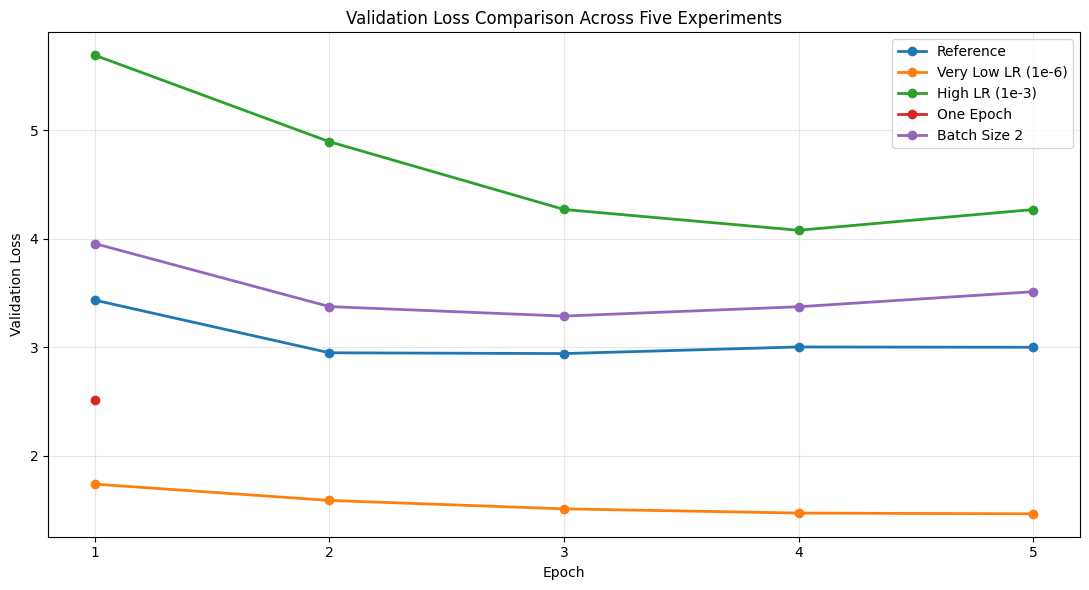

Validation loss graph saved to: /content/scientific_reasoning_project/validation_loss_comparison.png


In [14]:
import matplotlib.pyplot as plt
import os

# Epoch-level validation loss recorded during the five experiments
validation_results = {
    "Reference": [3.434207, 2.948581, 2.941492, 3.002418, 2.999478],
    "Very Low LR (1e-6)": [1.736819, 1.586755, 1.508869, 1.470104, 1.463302],
    "High LR (1e-3)": [5.693478, 4.895766, 4.270935, 4.078820, 4.270192],
    "One Epoch": [2.512753],
    "Batch Size 2": [3.955888, 3.374858, 3.287297, 3.373451, 3.512133]
}

plt.figure(figsize=(11, 6))

for experiment, losses in validation_results.items():
    epochs = range(1, len(losses) + 1)
    plt.plot(epochs, losses, marker='o', linewidth=2, label=experiment)

plt.title("Validation Loss Comparison Across Five Experiments")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph in the project results directory
output_dir = "/content/scientific_reasoning_project"
os.makedirs(output_dir, exist_ok=True)

graph_path = os.path.join(output_dir, "validation_loss_comparison.png")
plt.savefig(graph_path, dpi=300, bbox_inches="tight")

plt.show()

print("Validation loss graph saved to:", graph_path)

In [17]:
!pip install -q huggingface_hub

In [18]:
from huggingface_hub import notebook_login

notebook_login()

In [19]:
import os

checkpoint_path = "/content/scientific_reasoning_project/Very_low_LR_1e-6_"

print("Checkpoint folder exists:", os.path.exists(checkpoint_path))
print("\nFiles inside checkpoint:")

for file in os.listdir(checkpoint_path):
    path = os.path.join(checkpoint_path, file)
    size_mb = os.path.getsize(path) / (1024 * 1024) if os.path.isfile(path) else 0
    print(f"{file} — {size_mb:.2f} MB")

Checkpoint folder exists: True

Files inside checkpoint:
final_model — 0.00 MB


In [20]:
import os

model_path = "/content/scientific_reasoning_project/Very_low_LR_1e-6_/final_model"

print("Model folder exists:", os.path.exists(model_path))

for root, dirs, files in os.walk(model_path):
    for file in files:
        full_path = os.path.join(root, file)
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"{os.path.relpath(full_path, model_path)} — {size_mb:.2f} MB")

Model folder exists: True
model.safetensors — 1884.62 MB
chat_template.jinja — 0.00 MB
generation_config.json — 0.00 MB
config.json — 0.00 MB
training_args.bin — 0.01 MB
tokenizer.json — 10.89 MB
tokenizer_config.json — 0.00 MB


In [21]:
from huggingface_hub import HfApi

api = HfApi()

api.upload_folder(
    folder_path="/content/scientific_reasoning_project/Very_low_LR_1e-6_/final_model",
    repo_id="sansyed/SciReason-AI",
    repo_type="model",
    ignore_patterns=["training_args.bin"],
    commit_message="Upload fine-tuned SciReason AI model"
)

print("Model uploaded successfully!")

Model uploaded successfully!
